<a href="https://colab.research.google.com/github/manyaAM123/deep_learning/blob/main/exp7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.0219
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0030
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.2817e-04
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.7465e-04
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.0267e-04
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.9958e-04
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.9340e-04
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.0338e-04
Epoch 9/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.5335e-04
Epoch 10/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.4821e-04
Epoch 11/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.8953e-04
Epoch 12/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.8720e-04
Epoch 13/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9261e-04
Epoch 14/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.5216e-04
Epoch 15/20
25/25 ━━━━━━━━━━━━━━━━━━

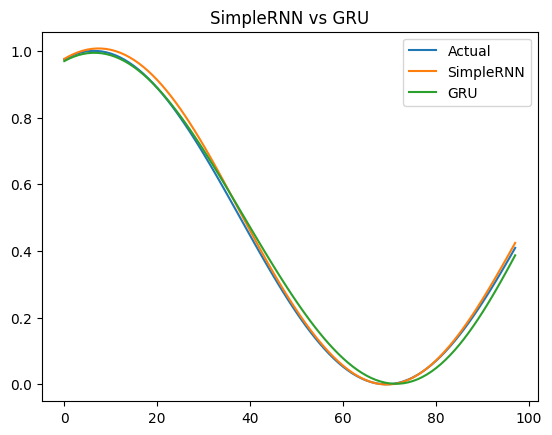

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# Generate sample time-series data
np.random.seed(42)

data = np.sin(np.arange(500) * 0.05)
data = data.reshape(-1, 1)

# Normalize data
scaler = MinMaxScaler()
data = scaler.fit_transform(data)

# Create sliding window sequences
X = []
y = []

window = 10

for i in range(len(data) - window):
    X.append(data[i:i+window])
    y.append(data[i+window])

X = np.array(X)
y = np.array(y)

# Split training and testing data
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# SimpleRNN model
rnn = Sequential([
    SimpleRNN(32, activation='tanh',
              input_shape=(10, 1)),
    Dense(1)


])

rnn.compile(optimizer='adam', loss='mse')

rnn.fit(X_train, y_train,
        epochs=20, batch_size=16,
        verbose=1)

# GRU model
gru = Sequential([
    GRU(32, activation='tanh',
        input_shape=(10, 1)),
    Dense(1)
])

gru.compile(optimizer='adam', loss='mse')

gru.fit(X_train, y_train,
        epochs=20, batch_size=16,
        verbose=1)

# Predictions
rnn_pred = rnn.predict(X_test)
gru_pred = gru.predict(X_test)

# Calculate errors
rnn_mse = mean_squared_error(y_test, rnn_pred)
gru_mse = mean_squared_error(y_test, gru_pred)

print("SimpleRNN MSE:", rnn_mse)
print("GRU MSE:", gru_mse)

# Plot comparison
plt.plot(y_test, label='Actual')
plt.plot(rnn_pred, label='SimpleRNN')
plt.plot(gru_pred, label='GRU')

plt.legend()
plt.title("SimpleRNN vs GRU")
plt.show()


Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 93ms/step - loss: 0.0081
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0056
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0049
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0052
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0051
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0052
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0047
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0059
Epoch 9/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0045
Epoch 10/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0045
Epoch 11/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0047
Epoch 12/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0052
Epoch 13/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0049
Epoch 14/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0047
Epoch 15/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0053
Epoch 16/20
25/25 ━━━━━━

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
SimpleRNN MSE: 1.4653948580613274
GRU MSE: 1.368872112434326
SimpleRNN MAE: 0.9731622992001802
GRU MAE: 0.9445481337278883


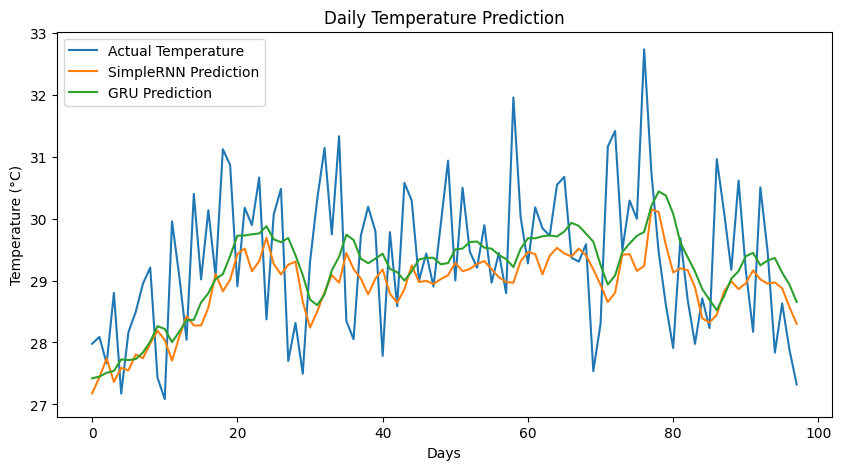

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Generate sample temperature data
np.random.seed(42)

days = np.arange(500)

temperature = (
    25
    + 5 * np.sin(2 * np.pi * days / 365)
    + np.random.normal(0, 1, 500)
)

df = pd.DataFrame({'Temperature': temperature})

# 2. Normalize data
scaler = MinMaxScaler()
data = scaler.fit_transform(df[['Temperature']])

# 3. Create sliding window sequences
X, y = [], []
window = 10

for i in range(len(data) - window):
    X.append(data[i:i+window])
    y.append(data[i+window])

X = np.array(X)
y = np.array(y)

# 4. Split data
split = int(0.8 * len(X))

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# 5. SimpleRNN model
rnn = Sequential([
    SimpleRNN(32, activation='tanh',
              input_shape=(10, 1)),
    Dense(1)
])

rnn.compile(optimizer='adam', loss='mse')

rnn.fit(X_train, y_train,
        epochs=20, batch_size=16, verbose=1)

# 6. GRU model
gru = Sequential([
    GRU(32, activation='tanh',
        input_shape=(10, 1)),
    Dense(1)
])

gru.compile(optimizer='adam', loss='mse')

gru.fit(X_train, y_train,
        epochs=20, batch_size=16, verbose=1)

# 7. Prediction
rnn_pred = rnn.predict(X_test)
gru_pred = gru.predict(X_test)

# Convert to original temperature scale
actual = scaler.inverse_transform(y_test)
rnn_pred = scaler.inverse_transform(rnn_pred)
gru_pred = scaler.inverse_transform(gru_pred)

# 8. Evaluate models
print("SimpleRNN MSE:",
      mean_squared_error(actual, rnn_pred))

print("GRU MSE:",
      mean_squared_error(actual, gru_pred))

print("SimpleRNN MAE:",
      mean_absolute_error(actual, rnn_pred))

print("GRU MAE:",
      mean_absolute_error(actual, gru_pred))

# 9. Plot temperature prediction
plt.figure(figsize=(10,5))

plt.plot(actual, label='Actual Temperature')
plt.plot(rnn_pred, label='SimpleRNN Prediction')
plt.plot(gru_pred, label='GRU Prediction')

plt.xlabel('Days')
plt.ylabel('Temperature (°C)')
plt.title('Daily Temperature Prediction')

plt.legend()
plt.show()


Using Colab cache for faster access to the 'daily-climate-time-series-data' dataset.
Training shape: (1250, 10, 4)
Testing shape: (316, 10, 4)

Training SimpleRNN...
Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0661 - mae: 0.1992
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0140 - mae: 0.0911
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0096 - mae: 0.0764
Epoch 4/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0079 - mae: 0.0699
Epoch 5/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0070 - mae: 0.0661
Epoch 6/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0064 - mae: 0.0637
Epoch 7/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0061 - mae: 0.0618
Epoch 8/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0057 - mae: 0.0597
Epoch 9/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0052 - mae: 0.0574
Epoch 10/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0048 - mae: 0.0549
Epoch 11/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 

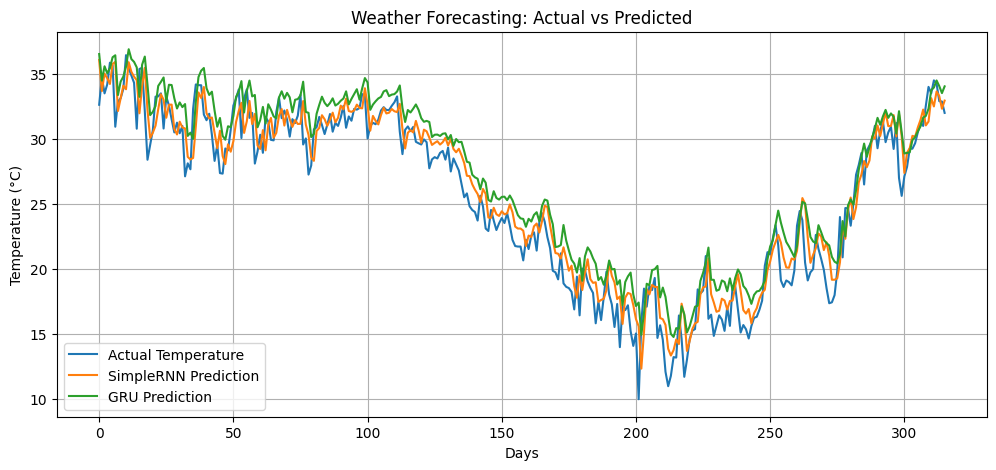

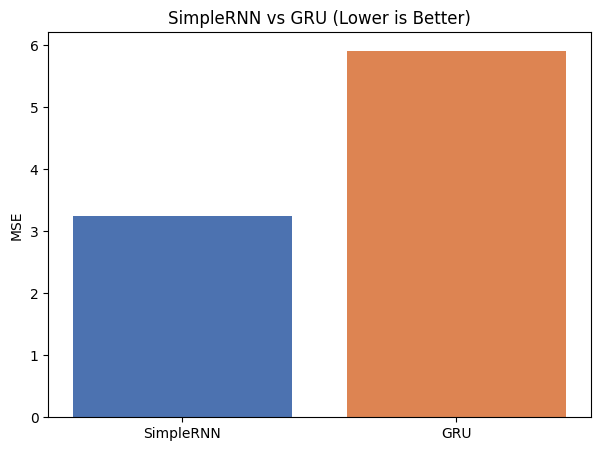

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step

NEXT DAY TEMPERATURE
SimpleRNN: 32.37 °C
GRU:       33.49 °C


In [ ]:
# 1. Import libraries
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense, Input

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# 2. Download and load the Kaggle dataset
path = kagglehub.dataset_download("sumanthvrao/daily-climate-time-series-data")
train_df = pd.read_csv(os.path.join(path, "DailyDelhiClimateTrain.csv"))
test_df = pd.read_csv(os.path.join(path, "DailyDelhiClimateTest.csv"))

# Combine train and test CSVs so we can perform a clean 80/20 split
df = pd.concat([train_df, test_df], ignore_index=True)

# 3. Preprocessing
df.columns = df.columns.str.strip().str.lower()
features = ['meantemp', 'humidity', 'wind_speed', 'meanpressure']

df = df[features].copy()
df = df.apply(pd.to_numeric, errors='coerce')
df.dropna(inplace=True)

# 4. Normalize data (fit scalers ONLY on the training split to prevent data leakage)
X_data = df[features].values
y_data = df[['meantemp']].values

split = int(len(df) * 0.8)

x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()

x_scaler.fit(X_data[:split])
y_scaler.fit(y_data[:split])

X_scaled = x_scaler.transform(X_data)
y_scaled = y_scaler.transform(y_data)

# 5. Create sliding window sequences
X, y = [], []
window = 10

for i in range(len(X_scaled) - window):
    X.append(X_scaled[i:i+window])
    y.append(y_scaled[i+window])

X = np.array(X)
y = np.array(y)

# 6. Split training and testing data
train_size = split - window

X_train = X[:train_size]
X_test = X[train_size:]
y_train = y[:train_size]
y_test = y[train_size:]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# 7. Build SimpleRNN model
rnn_model = Sequential([
    Input(shape=(10, 4)),
    SimpleRNN(32, activation='tanh'),
    Dense(1)
])

rnn_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# 8. Train SimpleRNN
print("\nTraining SimpleRNN...")
rnn_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    shuffle=False,
    verbose=1
)

# 9. Build GRU model
gru_model = Sequential([
    Input(shape=(10, 4)),
    GRU(32, activation='tanh'),
    Dense(1)
])

gru_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# 10. Train GRU
print("\nTraining GRU...")
gru_model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=16,
    shuffle=False,
    verbose=1
)

# 11. Prediction
rnn_pred = rnn_model.predict(X_test)
gru_pred = gru_model.predict(X_test)

# 12. Convert predictions to original scale
actual = y_scaler.inverse_transform(y_test)
rnn_pred = y_scaler.inverse_transform(rnn_pred)
gru_pred = y_scaler.inverse_transform(gru_pred)

# 13. Evaluate models
rnn_mse = mean_squared_error(actual, rnn_pred)
gru_mse = mean_squared_error(actual, gru_pred)
rnn_mae = mean_absolute_error(actual, rnn_pred)
gru_mae = mean_absolute_error(actual, gru_pred)

print("\nMODEL PERFORMANCE")
print(f"SimpleRNN MSE: {rnn_mse:.4f}")
print(f"GRU MSE:       {gru_mse:.4f}")
print(f"SimpleRNN MAE: {rnn_mae:.4f}")
print(f"GRU MAE:       {gru_mae:.4f}")

# 14. Plot temperature prediction
plt.figure(figsize=(12, 5))
plt.plot(actual, label='Actual Temperature')
plt.plot(rnn_pred, label='SimpleRNN Prediction')
plt.plot(gru_pred, label='GRU Prediction')
plt.xlabel('Days')
plt.ylabel('Temperature (°C)')
plt.title('Weather Forecasting: Actual vs Predicted')
plt.legend()
plt.grid(True)
plt.show()

# 15. Compare model performance
plt.figure(figsize=(7, 5))
plt.bar(['SimpleRNN', 'GRU'], [rnn_mse, gru_mse], color=['#4C72B0', '#DD8452'])
plt.ylabel('MSE')
plt.title('SimpleRNN vs GRU (Lower is Better)')
plt.show()
last_sequence = X_scaled[-10:].reshape(1, 10, 4)

next_rnn = rnn_model.predict(last_sequence)
next_gru = gru_model.predict(last_sequence)

print("\nNEXT DAY TEMPERATURE")
print(f"SimpleRNN: {y_scaler.inverse_transform(next_rnn)[0][0]:.2f} °C")
print(f"GRU:       {y_scaler.inverse_transform(next_gru)[0][0]:.2f} °C")